# Módulo 2 — Práctica: recorte de dominio y periodo

Ejercicio 3 de la práctica del Día 3 (ver [`README.md`](../README.md)).

> **📍 Nota para curso con 2 grupos (Norte/Sur de Perú):** este notebook recorta a la costa central del Perú (`lat_norte, lat_sur = -8.0, -14.0`). Para 2 grupos, cada uno recorta a su propia sub-zona, coherente con el reparto de ciudades del Día 1:
> - **Grupo 1 (Norte):** `lat_norte, lat_sur = -3.0, -13.0` · `lon_oeste, lon_este = -81.5, -76.5` (cubre Piura, Tumbes, Chiclayo, Lima).
> - **Grupo 2 (Sur):** `lat_norte, lat_sur = -13.0, -19.0` · `lon_oeste, lon_este = -73.0, -69.5` (cubre Cuzco, Arequipa, Tacna).
> Cambiar solo estos 4 valores en el "Paso 2" — el resto del notebook no cambia.

In [1]:
from synth_data import era5_like_dataset
import xarray as xr

ds = era5_like_dataset(
    lat_first=15.0, lat_last=-25.0, lon_first=-85.0, lon_last=-65.0,
    nlat=41, nlon=21, start="2026-01-10", periods=14 * 24, seed=3,
)
print("Dominio completo:", dict(ds.sizes))
print("Latitud:  ", float(ds.latitude.max()), "a", float(ds.latitude.min()))
print("Longitud: ", float(ds.longitude.min()), "a", float(ds.longitude.max()))
print("Tiempo:   ", str(ds.time.min().values), "a", str(ds.time.max().values))

Dominio completo: {'time': 336, 'latitude': 41, 'longitude': 21}
Latitud:   15.0 a -25.0
Longitud:  -85.0 a -65.0
Tiempo:    2026-01-10T00:00:00.000000 a 2026-01-23T23:00:00.000000


## Paso 1 — Verificar el orden de la latitud antes de recortar

In [2]:
lat = ds["latitude"].values
orden_descendente = lat[0] > lat[-1]
print("¿Latitud descendente?", orden_descendente)

¿Latitud descendente? True


## Paso 2 — Recortar el dominio a la costa central del Perú

In [3]:
# Área de interés: costa central (aprox.)
lat_norte, lat_sur = -8.0, -14.0
lon_oeste, lon_este = -78.5, -75.5

if orden_descendente:
    recorte = ds.sel(latitude=slice(lat_norte, lat_sur), longitude=slice(lon_oeste, lon_este))
else:
    recorte = ds.sel(latitude=slice(lat_sur, lat_norte), longitude=slice(lon_oeste, lon_este))

print("Dominio recortado:", dict(recorte.sizes))
assert recorte.sizes["latitude"] > 0 and recorte.sizes["longitude"] > 0, "¡Recorte vacío!"
print("Recorte válido (no vacío).")

Dominio recortado: {'time': 336, 'latitude': 7, 'longitude': 3}
Recorte válido (no vacío).


## Paso 3 — Recortar el periodo a una semana

In [4]:
recorte_periodo = recorte.sel(time=slice("2026-01-12", "2026-01-19"))
print("Pasos de tiempo en el periodo recortado:", recorte_periodo.sizes["time"])
print("Primer y último tiempo:", str(recorte_periodo.time.min().values), "-",
      str(recorte_periodo.time.max().values))

Pasos de tiempo en el periodo recortado: 192
Primer y último tiempo: 2026-01-12T00:00:00.000000 - 2026-01-19T23:00:00.000000


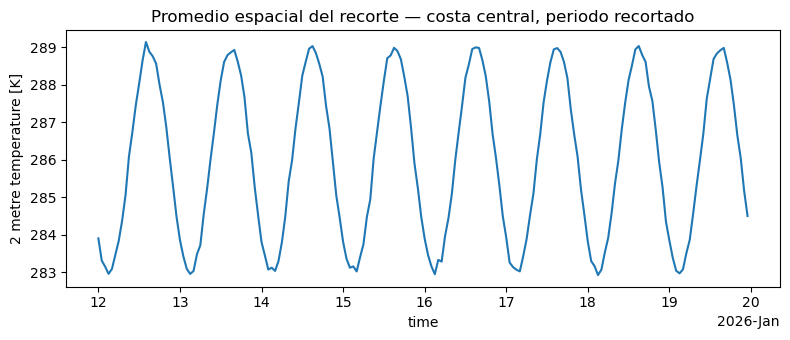

In [5]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 3.5))
recorte_periodo["t2m"].mean(dim=["latitude", "longitude"]).plot(ax=ax)
ax.set_title("Promedio espacial del recorte — costa central, periodo recortado")
fig.tight_layout()
plt.show()

## Paso 4 — Guardar el subconjunto recortado

In [6]:
recorte_periodo.to_netcdf("recorte_costa_central.nc")
print("Archivo guardado: recorte_costa_central.nc")
print(f"Tamaño del dominio original: {ds.sizes['latitude']} x {ds.sizes['longitude']} x {ds.sizes['time']}")
print(f"Tamaño del recorte:          {recorte_periodo.sizes['latitude']} x "
      f"{recorte_periodo.sizes['longitude']} x {recorte_periodo.sizes['time']}")

Archivo guardado: recorte_costa_central.nc
Tamaño del dominio original: 41 x 21 x 336
Tamaño del recorte:          7 x 3 x 192


## Visualización rápida de verificación

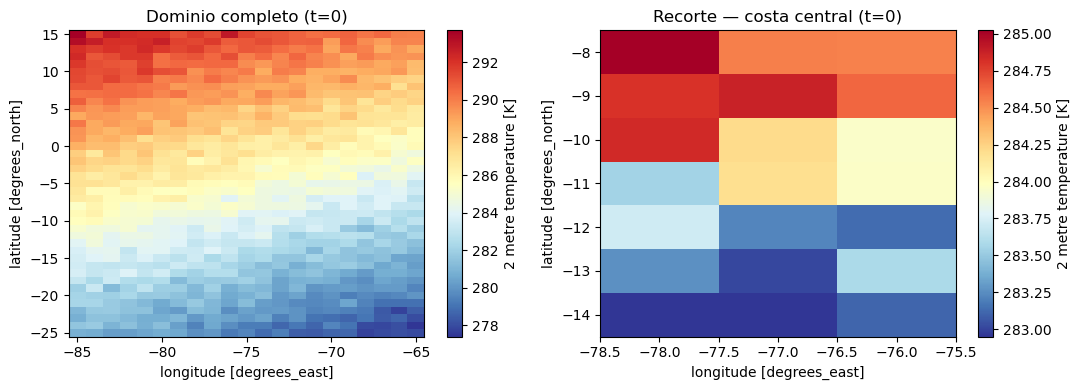

In [7]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

ds["t2m"].isel(time=0).plot(ax=axes[0], cmap="RdYlBu_r")
axes[0].set_title("Dominio completo (t=0)")

recorte_periodo["t2m"].isel(time=0).plot(ax=axes[1], cmap="RdYlBu_r")
axes[1].set_title("Recorte — costa central (t=0)")

fig.tight_layout()
plt.show()

## Cierre

Entregable parcial: este notebook + `recorte_costa_central.nc`. Continuar
con [`04_entregable_interpolacion.ipynb`](04_entregable_interpolacion.ipynb).